In [1]:
import math, os, itertools, struct, warnings
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import matplotlib.pyplot as plt
from dataclasses import dataclass
warnings.filterwarnings('ignore')

In [2]:
import torch
import torchaudio
print(f'PyTorch   : {torch.__version__}')
print(f'torchaudio: {torchaudio.__version__}')
print(f'CUDA      : {torch.cuda.is_available()}')

PyTorch   : 2.10.0+cu128
torchaudio: 2.10.0+cu128
CUDA      : True


In [3]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Running on: {DEVICE}')

# ── Vocabulary (vocabulary.txt: a-z, apostrophe, space; blank appended last) ──
VOCAB_CHARS = list('abcdefghijklmnopqrstuvwxyz') + ["'", ' ']
BLANK_INDEX  = len(VOCAB_CHARS)   # 28  (CTC blank)
NUM_CLASSES  = len(VOCAB_CHARS) + 1  # 29
INT2CHAR     = {i: c for i, c in enumerate(VOCAB_CHARS)}
# (blank has no character)

@dataclass
class Config:
    # Audio front-end (defaults)
    sample_rate      : int   = 16_000
    frame_length_ms  : int   = 20      # → frame_size  = 320 samples
    frame_stride_ms  : int   = 10      # → stride_size = 160 samples
    feature_norm     : bool  = True
    freq_bins        : int   = 161     # FFT bins kept  (= frame_size//2 + 1)
    # Semantic encoder CNN  (conv_filters=32)
    conv_filters     : int   = 32
    # Semantic encoder RNN  
    num_rnn_layers   : int   = 7
    rnn_hidden_size  : int   = 800
    rnn_type         : str   = 'gru'
    is_bidirectional : bool  = True
    use_bias         : bool  = True
    # Channel codec
    num_channel_units: int   = 40
    num_classes      : int   = NUM_CLASSES   # 29
    # BN hyper-params (TF: decay=0.997, eps=1e-5)
    bn_eps           : float = 1e-5
    bn_momentum      : float = 0.003   # PyTorch momentum = 1 - TF decay

CFG = Config()
print(CFG)

Running on: cuda
Config(sample_rate=16000, frame_length_ms=20, frame_stride_ms=10, feature_norm=True, freq_bins=161, conv_filters=32, num_rnn_layers=7, rnn_hidden_size=800, rnn_type='gru', is_bidirectional=True, use_bias=True, num_channel_units=40, num_classes=29, bn_eps=1e-05, bn_momentum=0.003)


In [4]:
def compute_spectrogram_feature(audio_samples: np.ndarray,
                                 sample_rate: int = 16000,
                                 frame_length: int = 20,
                                 frame_stride: int = 10,
                                 max_freq: float = None,
                                 eps: float = 1e-14) -> np.ndarray:
    """Exact replica of deepscst.py:compute_spectrogram_feature.
    Returns: (T, 161) float32 log-power spectrogram.
    """
    if max_freq is None:
        max_freq = sample_rate / 2
    stride_size = int(0.001 * sample_rate * frame_stride)   # 160
    frame_size  = int(0.001 * sample_rate * frame_length)   # 320

    truncate_size = (len(audio_samples) - frame_size) % stride_size
    audio_samples = audio_samples[:len(audio_samples) - truncate_size]

    nshape  = (frame_size, (len(audio_samples) - frame_size) // stride_size + 1)
    nstrides = (audio_samples.strides[0], audio_samples.strides[0] * stride_size)
    frames  = np.lib.stride_tricks.as_strided(audio_samples, shape=nshape, strides=nstrides)

    weighting = np.hanning(frame_size)[:, None]
    fft = np.fft.rfft(frames * weighting, axis=0)
    fft = np.absolute(fft) ** 2
    scale = np.sum(weighting ** 2) * sample_rate
    fft[1:-1, :] *= (2.0 / scale)
    fft[(0, -1), :] /= scale

    freqs = float(sample_rate) / frame_size * np.arange(fft.shape[0])
    ind   = np.where(freqs <= max_freq)[0][-1] + 1
    specgram = np.log(fft[:ind, :] + eps)
    specgram = np.transpose(specgram, (1, 0))  # (T, F)
    return specgram.astype(np.float32)


def normalize_audio_feature(features: np.ndarray) -> np.ndarray:
    """Zero-mean, unit-variance normalisation over time axis."""
    mean = np.mean(features, axis=0)
    var  = np.var(features,  axis=0)
    return ((features - mean) / (np.sqrt(var) + 1e-6)).astype(np.float32)


def preprocess_wav(wav_path: str, cfg: Config = CFG) -> torch.Tensor:
    """
    Load a .wav file, resample to 16 kHz mono, compute spectrogram.
    Returns: (1, T, 161, 1) float32 tensor  (batch=1, time, freq, channel)
    """
    waveform, sr = torchaudio.load(wav_path)
    # Stereo → mono
    if waveform.shape[0] > 1:
        waveform = waveform.mean(dim=0, keepdim=True)
    # Resample
    if sr != cfg.sample_rate:
        waveform = torchaudio.functional.resample(waveform, sr, cfg.sample_rate)
    audio_np = waveform.squeeze().numpy().astype(np.float64)

    feat = compute_spectrogram_feature(audio_np, cfg.sample_rate,
                                        cfg.frame_length_ms, cfg.frame_stride_ms)
    if cfg.feature_norm:
        feat = normalize_audio_feature(feat)

    # (T, F) → (1, T, F, 1)
    feat = feat[np.newaxis, :, :, np.newaxis]
    return torch.from_numpy(feat)   # float32


print('Pre-processing helpers ready ✓')

Pre-processing helpers ready ✓


In [5]:
# ══════════════════════════════════════════════════════════════════════════════
# 4-A  CNN-BN Block 
# ══════════════════════════════════════════════════════════════════════════════
class ConvBNBlock(nn.Module):
    """
    Manual-padding 2-D Conv → BatchNorm → ReLU6.
    Input  : (B, C_in, T, F)
    Output : (B, C_out, T', F')
    """
    def __init__(self, in_ch, out_ch, kernel, stride, pad, cfg: Config):
        super().__init__()
        self.pad_t, self.pad_f = pad   # (time_pad, freq_pad)
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size=kernel,
                              stride=stride, padding=0, bias=False)
        self.bn   = nn.BatchNorm2d(out_ch, eps=cfg.bn_eps, momentum=cfg.bn_momentum)

    def forward(self, x):
        # F.pad order: (left, right, top, bottom) for last two dims
        x = F.pad(x, (self.pad_f, self.pad_f, self.pad_t, self.pad_t))
        return F.relu6(self.bn(self.conv(x)))


# ══════════════════════════════════════════════════════════════════════════════
# 4-B  BiGRU-BN Block  
# ══════════════════════════════════════════════════════════════════════════════
class RNNBNBlock(nn.Module):
    """
    Bidirectional GRU (or LSTM / vanilla RNN) followed by BatchNorm1d.
    Input  : (B, T, F_in)
    Output : (B, T, 2*hidden)  [bidirectional]
    BN is applied over the feature dim after merging B and T.
    """
    _RNN_TYPES = {'gru': nn.GRU, 'lstm': nn.LSTM, 'rnn': nn.RNN}

    def __init__(self, input_size, hidden_size, rnn_type='gru',
                 bidirectional=True, cfg: Config = CFG):
        super().__init__()
        rnn_cls = self._RNN_TYPES[rnn_type]
        self.rnn = rnn_cls(input_size, hidden_size, batch_first=True,
                            bidirectional=bidirectional)
        out_size = hidden_size * (2 if bidirectional else 1)
        self.bn  = nn.BatchNorm1d(out_size, eps=cfg.bn_eps, momentum=cfg.bn_momentum)

    def forward(self, x):
        out, _ = self.rnn(x)           # (B, T, out_size)
        B, T, F = out.shape
        out = self.bn(out.reshape(B * T, F)).reshape(B, T, F)
        return out


# ══════════════════════════════════════════════════════════════════════════════
# 4-C  Physical Channel Layer  
# ══════════════════════════════════════════════════════════════════════════════
class ChannelLayer(nn.Module):
    """
    Simulates AWGN / Rayleigh / Rician fading with perfect-CSI equalization.

    channel : 'AWGN' | 'Rayleigh' | 'Rician'
    snr_db  : signal-to-noise ratio in dB
    """
    def forward(self, x_norm: torch.Tensor,
                channel: str = 'AWGN', snr_db: float = 10.0) -> torch.Tensor:
        """
        x_norm : (B, T, 2)  — power-normalised complex symbols [real, imag]
        returns : (B, T, 2)  — equalized received symbols
        """
        B, T, _ = x_norm.shape
        dev = x_norm.device

        snr_linear = 10 ** (snr_db / 10.0)
        std = math.sqrt(1.0 / snr_linear)

        if channel == 'AWGN':
            awgn_f, ray_f, rice_f = 1.0, 0.0, 0.0
        elif channel == 'Rayleigh':
            awgn_f, ray_f, rice_f = 0.0, 1.0, 0.0
        elif channel == 'Rician':
            awgn_f, ray_f, rice_f = 0.0, 0.5, 0.5
        else:
            raise ValueError(f'Unknown channel: {channel}')

        # h: (B, T, 1, 2)  Rician/Rayleigh fading
        h_raw = torch.randn(B, T, 1, 2, device=dev)
        h = (math.sqrt(rice_f) + math.sqrt(ray_f) * h_raw) / math.sqrt(2.0)

        noise  = torch.randn(B, T, 1, 2, device=dev) * std
        x_e    = x_norm.unsqueeze(2)   # (B,T,1,2)

        xr, xi = x_e[..., 0], x_e[..., 1]
        hr, hi = h[..., 0],   h[..., 1]
        nr, ni = noise[..., 0], noise[..., 1]

        # Complex multiply: y = h*x + n
        hxr = xr * (hr + awgn_f) - xi * hi
        hxi = xr * hi             + xi * (hr + awgn_f)
        yr  = hxr + nr
        yi  = hxi + ni

        # Perfect-CSI equalization: x_hat = h* y / |h|^2
        rr  = yr * (hr + awgn_f) + yi * hi
        ri  = yi * (hr + awgn_f) - yr * hi
        hh  = hr * hr + hi * hi

        x_hat_r = rr / (hh + awgn_f)   # (B,T,1)
        x_hat_i = ri / (hh + awgn_f)

        return torch.cat([x_hat_r, x_hat_i], dim=-1).squeeze(2)  # (B,T,2)


print('Building blocks defined ✓')

Building blocks defined ✓


In [6]:
class DeepSCST(nn.Module):
    def __init__(self, cfg: Config = CFG):
        super().__init__()
        self.cfg = cfg
        C   = cfg.conv_filters
        NC  = cfg.num_classes
        NCU = cfg.num_channel_units

        self.cnn1 = ConvBNBlock(1, C, (41, 11), (2, 2), (20, 5), cfg)
        self.cnn2 = ConvBNBlock(C, C, (21, 11), (2, 1), (10, 5), cfg)

        self._rnn_input_size = None
        self._rnn_layers     = nn.ModuleList()

        rnn_out      = cfg.rnn_hidden_size * (2 if cfg.is_bidirectional else 1)
        self.sem_out = nn.Linear(rnn_out, NC, bias=cfg.use_bias)

        self.chan_enc1 = nn.Linear(NC,  NCU, bias=True)
        self.chan_enc2 = nn.Linear(NCU, NCU, bias=True)
        self.channel   = ChannelLayer()
        self.chan_dec1 = nn.Linear(NCU, NCU, bias=True)
        self.chan_dec2 = nn.Linear(NCU, NCU, bias=True)
        self.chan_dec3 = nn.Linear(NCU, NC,  bias=True)

    def _build_rnn_stack(self, input_size: int):
        cfg     = self.cfg
        rnn_out = cfg.rnn_hidden_size * (2 if cfg.is_bidirectional else 1)
        layers  = []
        for i in range(cfg.num_rnn_layers):
            in_sz = input_size if i == 0 else rnn_out
            layers.append(RNNBNBlock(in_sz, cfg.rnn_hidden_size,
                                      cfg.rnn_type, cfg.is_bidirectional, cfg))
        self._rnn_layers     = nn.ModuleList(layers)
        self._rnn_input_size = input_size
        self._rnn_layers.to(next(self.parameters()).device)

    def forward(self, x: torch.Tensor,
                channel: str = 'AWGN', snr_db: float = 10.0) -> torch.Tensor:
        x = x.permute(0, 3, 1, 2)              # (B,T,F,1) → (B,1,T,F)

        x = self.cnn1(x)                        # (B,32,T/2,81)
        x = self.cnn2(x)                        # (B,32,T/4,81)

        B, C, T2, F2 = x.shape
        x = x.permute(0, 2, 3, 1)              # (B,T/4,81,32)
        x = x.reshape(B, T2, F2 * C)           # (B,T/4,2592)

        if self._rnn_input_size is None:
            self._build_rnn_stack(F2 * C)
        for rnn_blk in self._rnn_layers:
            x = rnn_blk(x)                      # (B,T/4,1600)

        p  = F.softmax(self.sem_out(x), dim=-1) # (B,L,29)

        u  = F.relu6(self.chan_enc1(p))          # (B,L,40)
        u  = self.chan_enc2(u)                   # (B,L,40) — no activation

        B2, L, _ = u.shape
        sym = u.reshape(B2, L * (self.cfg.num_channel_units // 2), 2)  # (B,L*20,2)

        n_sym    = sym.shape[1]
        sym_norm = math.sqrt(n_sym / 2.0) * F.normalize(sym, p=2, dim=1)

        sym_hat = self.channel(sym_norm, channel, snr_db)  # (B,L*20,2)

        v = sym_hat.reshape(B2, L, self.cfg.num_channel_units)  # (B,L,40)
        v = F.relu6(self.chan_dec1(v))
        v = F.relu6(self.chan_dec2(v))
        return F.softmax(self.chan_dec3(v), dim=-1)             # (B,L,29)

    @property
    def sem_enc_out(self):
        return self.sem_out


# Quick sanity-check
model = DeepSCST(CFG).to(DEVICE)
dummy = torch.randn(2, 100, 161, 1).to(DEVICE)
with torch.no_grad():
    out = model(dummy, channel='AWGN', snr_db=10.0)
print(f'Model output shape: {out.shape}')   # expect (2, 25, 29)
total_params = sum(p.numel() for p in model.parameters())
print(f'Total parameters  : {total_params:,}')  # ~85.8 M 

Model output shape: torch.Size([2, 25, 29])
Total parameters  : 85,796,042


In [7]:
import itertools

class GreedyDecoder:
    """
    Implements CTC greedy decoding:
      1. argmax over class dimension
      2. merge consecutive repeated tokens
      3. remove blank tokens
    """
    def __init__(self, labels: list, blank_index: int = BLANK_INDEX):
        self.labels      = labels
        self.blank_index = blank_index
        self.int2char    = {i: c for i, c in enumerate(labels)}

    def decode(self, logits: np.ndarray) -> str:
        """
        logits : (L, 29) numpy array of per-step probabilities
        returns: decoded string
        """
        best  = list(np.argmax(logits, axis=1))
        merge = [k for k, _ in itertools.groupby(best)]
        chars = [self.int2char[k] for k in merge if k != self.blank_index]
        return ''.join(chars)

    def decode_tensor(self, logits: torch.Tensor) -> str:
        """Convenience: accepts a (L, 29) or (1, L, 29) torch Tensor."""
        if logits.dim() == 3:
            logits = logits[0]
        return self.decode(logits.cpu().detach().numpy())


decoder = GreedyDecoder(VOCAB_CHARS, blank_index=BLANK_INDEX)
print('Greedy decoder ready ✓')

Greedy decoder ready ✓


In [8]:
!pip install jiwer --quiet          # CER / WER
!pip install soundfile --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 34.2 MB/s eta 0:00:0000:0100:01


In [9]:
from jiwer import cer as compute_cer, wer as compute_wer

def evaluate(reference: str, hypothesis: str) -> dict:
    """Compute CER and WER exactly as in the paper (Section III-E)."""
    c = compute_cer(reference, hypothesis)
    w = compute_wer(reference, hypothesis)
    return {'CER': round(c, 4), 'WER': round(w, 4)}

In [10]:
class LJSpeechDataset(torch.utils.data.Dataset):
    """
    Lightweight LJSpeech dataset wrapper.
    Expects the standard LJSpeech layout:
        LJSpeech-1.1/
            wavs/LJ*.wav
            metadata.csv   (ID|transcript|normalized_transcript)
    """
    def __init__(self, root: str, cfg: Config = CFG, split: str = 'train',
                 train_ratio: float = 0.95):
        self.cfg  = cfg
        self.root = root
        meta_path = os.path.join(root, 'metadata.csv')
        with open(meta_path, encoding='utf-8') as f:
            lines = [l.strip().split('|') for l in f if l.strip()]
        # Use normalized transcript (col 2)
        items = [(os.path.join(root, 'wavs', l[0] + '.wav'),
                  l[2].lower()) for l in lines if len(l) >= 3]
        n_train = int(len(items) * train_ratio)
        self.items = items[:n_train] if split == 'train' else items[n_train:]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        wav_path, transcript = self.items[idx]
        features = preprocess_wav(wav_path, self.cfg)  # (1, T, 161, 1)
        features = features.squeeze(0)                  # (T, 161, 1)
        # Encode transcript → int list
        label = [CHAR2IDX[c] for c in transcript if c in CHAR2IDX]
        return features, torch.tensor(label, dtype=torch.long)


def collate_fn(batch):
    """Pad spectrogram & label sequences for CTC loss."""
    feats, labels = zip(*batch)
    feat_lens  = torch.tensor([f.shape[0] for f in feats])
    label_lens = torch.tensor([len(l) for l in labels])
    feats_pad  = torch.zeros(len(feats), max(feat_lens), 161, 1)
    for i, f in enumerate(feats):
        feats_pad[i, :f.shape[0]] = f
    labels_cat = torch.cat(labels)
    return feats_pad, labels_cat, feat_lens, label_lens


# Build vocabulary index (needed for CTC target)
CHAR2IDX = {c: i for i, c in enumerate(VOCAB_CHARS)}   # no blank in targets


def train_one_epoch(model, loader, optimizer, device, channel='Rician', snr_db=8.0):
    """One training epoch — matches Algorithm 1 in the paper."""
    model.train()
    ctc_loss = nn.CTCLoss(blank=BLANK_INDEX, reduction='mean', zero_infinity=True)
    total_loss = 0.0

    for feats, labels, feat_lens, label_lens in loader:
        feats  = feats.to(device)   # (B, T, 161, 1)
        labels = labels.to(device)

        logits = model(feats, channel=channel, snr_db=snr_db)  # (B, L, 29)

        # CTC expects (L, B, C) and log-probs
        log_probs = torch.log(logits.permute(1, 0, 2) + 1e-8)  # (L, B, 29)

        # Compute output lengths (same formula as deepscst.py)
        out_lens = torch.tensor([
            int((int((fl.item() - 1) / 2 + 1) - 1) / 2 + 1)
            for fl in feat_lens], dtype=torch.long)

        loss = ctc_loss(log_probs, labels, out_lens, label_lens)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    return total_loss / len(loader)


print('Training helpers defined ✓')



Training helpers defined ✓


In [ ]:
# Model Training 
LJSPEECH_ROOT = '/kaggle/input/datasets/mathurinache/the-lj-speech-dataset/LJSpeech-1.1'
train_ds = LJSpeechDataset(LJSPEECH_ROOT, split='train')
val_ds   = LJSpeechDataset(LJSPEECH_ROOT, split='val')
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=64,
                                            collate_fn=collate_fn, shuffle=True,
                                            num_workers=3, pin_memory=True)
model     = DeepSCST(CFG).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)   # paper: η=0.0001
for epoch in range(1, 61):    # paper: 60 epochs
    loss = train_one_epoch(model, train_loader, optimizer, DEVICE,
                           channel='Rician', snr_db=8.0)
    print(f'Epoch {epoch:3d}  CTC loss: {loss:.4f}')
    if epoch % 10 == 0:
        torch.save(model.state_dict(), f'saved_weights_{epoch}.pth')

In [12]:
model = DeepSCST(CFG).to(DEVICE)

# Build lazy RNN layers
dummy = torch.randn(1, 100, 161, 1).to(DEVICE)

with torch.no_grad():
    _ = model(dummy, channel='AWGN', snr_db=10)

In [ ]:
# # Load weights
# checkpoint_path = "/kaggle/input/models/madamabhiram/deep60/pytorch/default/1/saved_weights_60.pth"

# state_dict = torch.load(
#     checkpoint_path,
#     map_location=DEVICE
# )

# model.load_state_dict(state_dict)

# print("Model weights loaded successfully ✓")


# # Recreate optimizer
# optimizer = torch.optim.Adam(
#     model.parameters(),
#     lr=1e-4
# )


# # Continue training
# start_epoch = 11
# num_epochs = 60


# for epoch in range(start_epoch, num_epochs + 1):

#     loss = train_one_epoch(
#         model,
#         train_loader,
#         optimizer,
#         DEVICE,
#         channel='Rician',
#         snr_db=8.0
#     )

#     print(f'Epoch {epoch:3d}  CTC loss: {loss:.4f}')


#     if epoch % 10 == 0:
#         torch.save(
#             model.state_dict(),
#             f'saved_weights_{epoch}.pth'
#         )
#         print(f"Checkpoint saved: saved_weights_{epoch}.pth")

In [13]:
checkpoint_path = "/kaggle/input/models/madamabhiram/deep60/pytorch/default/1/saved_weights_60.pth"

state_dict = torch.load(
    checkpoint_path,
    map_location=DEVICE
)

model.load_state_dict(state_dict)

print("Model weights loaded successfully ✓")


Model weights loaded successfully ✓


In [37]:
# --------------------- Inference on a single audio file ---------------------

AUDIO_PATH = "/kaggle/input/datasets/mathurinache/the-lj-speech-dataset/LJSpeech-1.1/wavs/LJ001-0014.wav"      # <-- Change this to your audio file
CHANNEL = "AWGN"               # "AWGN", "Rayleigh", etc.
SNR_DB = 5

# Preprocess
x = preprocess_wav(AUDIO_PATH).to(DEVICE)

print(f"Input shape      : {x.shape}")

# Inference
model.eval()
with torch.no_grad():
    probs = model(
        x,
        channel=CHANNEL,
        snr_db=SNR_DB
    )

print(f"Output shape     : {probs.shape}")

# Decode
prediction = decoder.decode_tensor(probs)

print("\n==============================")
print("Predicted Text:")
print(prediction)
print("==============================")

# Optional: inspect raw CTC predictions
pred_ids = probs[0].argmax(dim=-1).cpu().numpy()

print("\nFrame-wise predicted indices:")
print(pred_ids)

print("\nFrame-wise predicted symbols:")
print([VOCAB_CHARS[i] if i != BLANK_INDEX else "<blank>" for i in pred_ids])

Input shape      : torch.Size([1, 993, 161, 1])
Output shape     : torch.Size([1, 249, 29])

Predicted Text:
and it was a matter of course that in the middle ages when the crafctsmen took care that beautiful for should always be a part of their productions whatever they were

Frame-wise predicted indices:
[28 28  0  0 13 13  3 27  8 19 19 27 22  0 18 27  0 27 27 12  0 19 28 19
  4 17 27 14  5 27 27  2 14 14 20 17 17 18 18  4 27 27 19 19  7  0 19 19
 27 28  8 13 28 27 19  7  4 27 12  8  3 28  3 11  4 27 27  0  0  6  6  4
  4  4 18 18 28 28 27 28 28 28 28 28 28 22  7  7  4 13 13 27 19  7  4 27
  2 17 17  0 28  5  2 19 19 18 18 28 12  4 13 13 27 19 14 28 14 14 10 27
  2 28  0 28 17 17  4 27 27 19 19  7  0  0 19 27 28  1  4  0 20 19 19  8
  8  5 20 11 11 27 27  5 14 28 17 17 28 27 18 18  7 14 20 11  3  3 27  0
 11 28 22  0  0 24 18 18 27 28  1  4 28 27  0 27 15  0 17 17 19 27 14  5
 27 27 19  7  4  8 17 27 15 17 14  3 28 20  2 19 19  8 28 14 13 13 18 18
 28 27 28 28 28 28 28 22  7  0 19 19

In [16]:
print(len(VOCAB_CHARS))

28


In [17]:
from tqdm import tqdm
from jiwer import cer, wer
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Starting Evaluation...


AWGN @ -5dB: 100%|██████████| 21/21 [00:15<00:00,  1.37it/s]


AWGN @ -5dB -> CER: 0.7836, WER: 1.3881


AWGN @ 0dB: 100%|██████████| 21/21 [00:14<00:00,  1.42it/s]


AWGN @ 0dB -> CER: 0.3663, WER: 0.7753


AWGN @ 5dB: 100%|██████████| 21/21 [00:15<00:00,  1.37it/s]


... (27 outputs left out)

Rician @ 15dB: 100%|██████████| 21/21 [00:17<00:00,  1.23it/s]


Rician @ 15dB -> CER: 0.0722, WER: 0.2977


Rician @ 20dB: 100%|██████████| 21/21 [00:17<00:00,  1.22it/s]


Rician @ 20dB -> CER: 0.0544, WER: 0.2482
Results saved to evaluation_results.csv
Plots saved to evaluation_plots.png


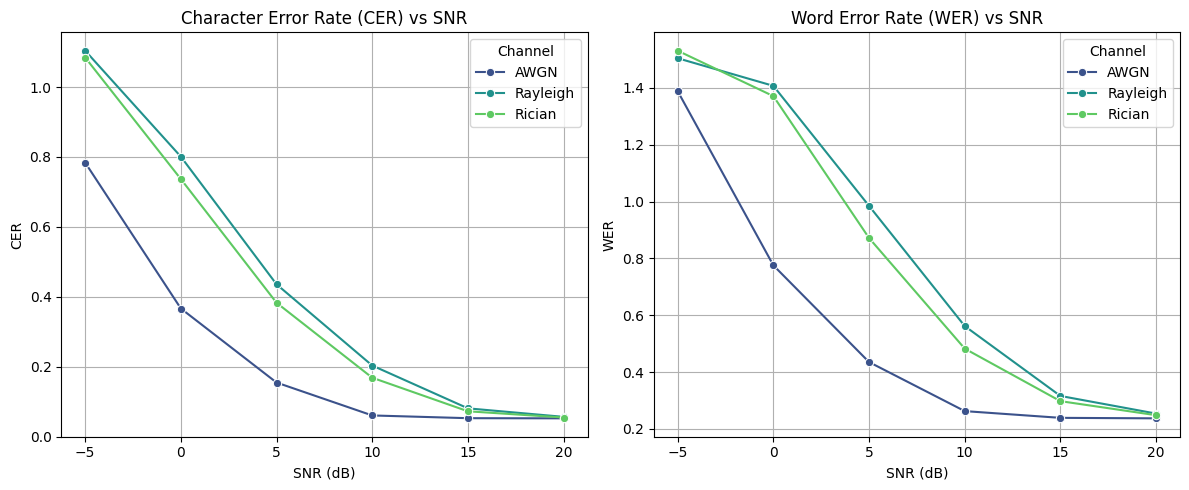

In [18]:
# Evaluate
CHANNELS = ['AWGN', 'Rayleigh', 'Rician']
SNR_DB_VALUES = [-5, 0, 5, 10, 15, 20]
BATCH_SIZE = 32

# 2. Load Test Data
test_ds = LJSpeechDataset(LJSPEECH_ROOT, split='val')
test_loader = torch.utils.data.DataLoader(
    test_ds, batch_size=BATCH_SIZE, collate_fn=collate_fn, 
    shuffle=False, num_workers=2, pin_memory=True
)
decoder = GreedyDecoder(VOCAB_CHARS, blank_index=BLANK_INDEX)
results = []

# 3. Iterate over Channels and SNRs
print("Starting Evaluation...")
with torch.no_grad():
    for channel in CHANNELS:
        for snr in SNR_DB_VALUES:
            total_cer = 0.0
            total_wer = 0.0
            num_samples = 0

            for feats, labels, feat_lens, label_lens in tqdm(test_loader, desc=f"{channel} @ {snr}dB"):
                feats = feats.to(DEVICE)
                # Forward pass
                probs = model(feats, channel=channel, snr_db=snr)  # (B, L, 29)

                # Decode and compute metrics
                for i in range(probs.shape[0]):
                    # Predicted text
                    pred_text = decoder.decode_tensor(probs[i])
                    # Reference text: decode labels
                    ref_indices = labels[sum(label_lens[:i]):sum(label_lens[:i+1])].tolist()
                    ref_text = ''.join([VOCAB_CHARS[idx] for idx in ref_indices])

                    total_cer += cer(ref_text, pred_text)
                    total_wer += wer(ref_text, pred_text)
                    num_samples += 1

            avg_cer = total_cer / num_samples if num_samples > 0 else 0
            avg_wer = total_wer / num_samples if num_samples > 0 else 0
            results.append({
                'Channel': channel, 
                'SNR (dB)': snr, 
                'CER': avg_cer, 
                'WER': avg_wer
            })
            print(f"{channel} @ {snr}dB -> CER: {avg_cer:.4f}, WER: {avg_wer:.4f}")

# 4. Save Table and Visualizations
df = pd.DataFrame(results)
df.to_csv('evaluation_results.csv', index=False)
print("Results saved to evaluation_results.csv")

# Plot CER vs SNR
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.lineplot(data=df, x='SNR (dB)', y='CER', hue='Channel', marker='o', palette='viridis')
plt.title('Character Error Rate (CER) vs SNR')
plt.grid(True)

# Plot WER vs SNR
plt.subplot(1, 2, 2)
sns.lineplot(data=df, x='SNR (dB)', y='WER', hue='Channel', marker='o', palette='viridis')
plt.title('Word Error Rate (WER) vs SNR')
plt.grid(True)

plt.tight_layout()
plt.savefig('evaluation_plots.png', dpi=300)
print("Plots saved to evaluation_plots.png")
plt.show()



In [19]:
df

,Channel,SNR (dB),CER,WER
0,AWGN,-5,0.783592,1.388070
1,AWGN,0,0.366261,0.775336
2,AWGN,5,0.154455,0.435160
3,AWGN,10,0.060316,0.262632
4,AWGN,15,0.052476,0.238951
5,AWGN,20,0.052034,0.237209
6,Rayleigh,-5,1.103922,1.504021
7,Rayleigh,0,0.800723,1.406864
8,Rayleigh,5,0.435506,0.984530
9,Rayleigh,10,0.203122,0.561798


In [20]:
# Classical Text Transciver
#########################################################
# Text <-> Bits
#########################################################
def text_to_bits(text):
    bits = []
    for c in text:
        b = format(ord(c), '08b')
        bits.extend([int(x) for x in b])
    return np.array(bits)

def bits_to_text(bits):
    bits = bits[:len(bits)//8*8]
    chars = []
    for i in range(0,len(bits),8):
        byte = bits[i:i+8]
        value = int(''.join(map(str,byte)),2)
        if value == 0:
            continue
        try:
            chars.append(chr(value))
        except:
            chars.append(" ")
    return ''.join(chars)
    
def bpsk_modulation(bits):
    return 2*bits - 1

def awgn_channel(signal,snr_db):
    snr = 10**(snr_db/10)
    noise_std = np.sqrt(1/(2*snr))
    noise = noise_std*np.random.randn(len(signal))
    return signal + noise

def rayleigh_channel(signal,snr_db):
    snr = 10**(snr_db/10)
    h = np.random.rayleigh(scale=1,size=len(signal))
    noise_std = np.sqrt(1/(2*snr))
    noise = noise_std*np.random.randn(len(signal))
    y = h*signal + noise
    y = y/h
    return y

def rician_channel(signal,snr_db,K=5):
    snr = 10**(snr_db/10)
    LOS = np.sqrt(K/(K+1))
    NLOS = np.sqrt(1/(2*(K+1)))*np.random.randn(len(signal))
    h = LOS + NLOS
    noise_std = np.sqrt(1/(2*snr))
    noise = noise_std*np.random.randn(len(signal))
    y = h*signal + noise
    y = y/h
    return y

def bpsk_demodulation(signal):
    return (signal>0).astype(np.int32)

def text_transceiver(text,channel,snr_db):
    bits = text_to_bits(text)
    symbols = bpsk_modulation(bits)
    if channel=="AWGN":
        rx = awgn_channel(symbols,snr_db)
    elif channel=="Rayleigh":
        rx = rayleigh_channel(symbols,snr_db)
    elif channel=="Rician":
        rx = rician_channel(symbols,snr_db)
    else:
        raise ValueError("Unknown channel")
    bits_hat = bpsk_demodulation(rx)
    text_hat = bits_to_text(bits_hat)
    return text_hat

In [27]:
import os
import csv

def get_transcript(audio_path, dataset_root):
    """
    Returns the normalized transcript for an LJSpeech audio file.
    Parameters
    ----------
    audio_path : str
        Path to a .wav file (e.g. LJ001-0014.wav)
    dataset_root : str
        Path to LJSpeech-1.1 directory
    Returns
    -------
    str
        Normalized transcript (lowercase)
    """
    metadata_path = os.path.join(dataset_root, "metadata.csv")
    file_id = os.path.splitext(os.path.basename(audio_path))[0]
    with open(metadata_path, "r", encoding="utf-8") as f:
        reader = csv.reader(f, delimiter="|")
        for row in reader:
            if row[0] == file_id:
                return row[2].lower()   # normalized transcript

    raise ValueError(f"Transcript not found for {file_id}")

In [36]:
AUDIO_PATH = "/kaggle/input/datasets/mathurinache/the-lj-speech-dataset/LJSpeech-1.1/wavs/LJ001-0014.wav"

# Load transcript
transcript = get_transcript(AUDIO_PATH, LJSPEECH_ROOT)  

print("Original Text:")
print(transcript)

received = text_transceiver(
    transcript,
    channel="AWGN",
    snr_db=5
)

print("\nReceived Text:")
print(received)

print(f"CER : {cer(transcript, received):.4f}")
print(f"WER : {wer(transcript, received):.4f}")

Original Text:
and it was a matter of course that in the middle ages, when the craftsmen took care that beautiful form should always be a part of their productions whatever they were,

Received Text:
and it was a matteò of coerse that in the middle ages, when the craftsmen took care that bea5tiful fo2m should always be a part of thair qroductáons whatever they werg,
CER : 0.0476
WER : 0.2258


In [21]:
baseline_results = []
print("Evaluating Classical Text Transceiver")
for channel in CHANNELS:
    for snr in SNR_DB_VALUES:
        total_cer = 0
        total_wer = 0
        total = 0
        for feats,labels,feat_lens,label_lens in tqdm(test_loader):
            start = 0
            for L in label_lens:
                end = start + L
                ref_indices = labels[start:end].tolist()
                start = end
                ref_text = ''.join(
                    VOCAB_CHARS[i] for i in ref_indices
                )
                pred_text = text_transceiver(
                    ref_text,
                    channel,
                    snr
                )
                total_cer += cer(ref_text,pred_text)
                total_wer += wer(ref_text,pred_text)
                total += 1

        baseline_results.append({
            "Model":"Text Transceiver",
            "Channel":channel,
            "SNR (dB)":snr,
            "CER":total_cer/total,
            "WER":total_wer/total
        })

Evaluating Classical Text Transceiver


100%|██████████| 21/21 [00:07<00:00,  2.85it/s]


In [22]:
base_df = pd.DataFrame(baseline_results)
base_df

,Model,Channel,SNR (dB),CER,WER
0,Text Transceiver,AWGN,-5,0.850780,0.999835
1,Text Transceiver,AWGN,0,0.483811,0.972182
2,Text Transceiver,AWGN,5,0.046408,0.282952
3,Text Transceiver,AWGN,10,0.000044,0.000305
4,Text Transceiver,AWGN,15,0.000000,0.000000
5,Text Transceiver,AWGN,20,0.000000,0.000000
6,Text Transceiver,Rayleigh,-5,0.809721,1.001126
7,Text Transceiver,Rayleigh,0,0.536294,0.983254
8,Text Transceiver,Rayleigh,5,0.247708,0.830747
9,Text Transceiver,Rayleigh,10,0.091336,0.483073


In [23]:
import pandas as pd

# Load DeepSC-ST results
deep_df = pd.read_csv("/kaggle/working/evaluation_results.csv")

# Add model name
deep_df["Model"] = "DeepSC-ST"

# Make sure both dataframes have the same column order
cols = ["Model", "Channel", "SNR (dB)", "CER", "WER"]

deep_df = deep_df[cols]
base_df = base_df[cols]

# Combine
comparison_df = pd.concat([deep_df, base_df], ignore_index=True)

# Save
comparison_df.to_csv("DeepSCST_vs_TextTransceiver.csv", index=False)

print(comparison_df.head())
print(comparison_df.tail())

       Model Channel  SNR (dB)       CER       WER
0  DeepSC-ST    AWGN        -5  0.783592  1.388070
1  DeepSC-ST    AWGN         0  0.366261  0.775336
2  DeepSC-ST    AWGN         5  0.154455  0.435160
3  DeepSC-ST    AWGN        10  0.060316  0.262632
4  DeepSC-ST    AWGN        15  0.052476  0.238951
               Model Channel  SNR (dB)       CER       WER
31  Text Transceiver  Rician         0  0.625827  0.992484
32  Text Transceiver  Rician         5  0.226500  0.796380
33  Text Transceiver  Rician        10  0.047814  0.285057
34  Text Transceiver  Rician        15  0.012678  0.087379
35  Text Transceiver  Rician        20  0.004488  0.030504


In [24]:
comparison_df

,Model,Channel,SNR (dB),CER,WER
0,DeepSC-ST,AWGN,-5,0.783592,1.388070
1,DeepSC-ST,AWGN,0,0.366261,0.775336
2,DeepSC-ST,AWGN,5,0.154455,0.435160
3,DeepSC-ST,AWGN,10,0.060316,0.262632
4,DeepSC-ST,AWGN,15,0.052476,0.238951
5,DeepSC-ST,AWGN,20,0.052034,0.237209
6,DeepSC-ST,Rayleigh,-5,1.103922,1.504021
7,DeepSC-ST,Rayleigh,0,0.800723,1.406864
8,DeepSC-ST,Rayleigh,5,0.435506,0.984530
9,DeepSC-ST,Rayleigh,10,0.203122,0.561798


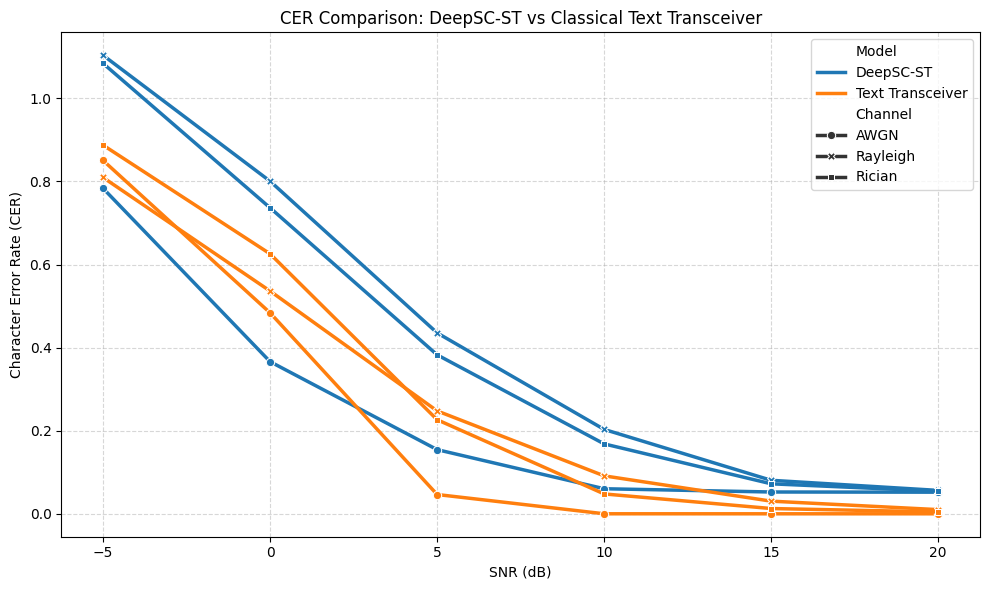

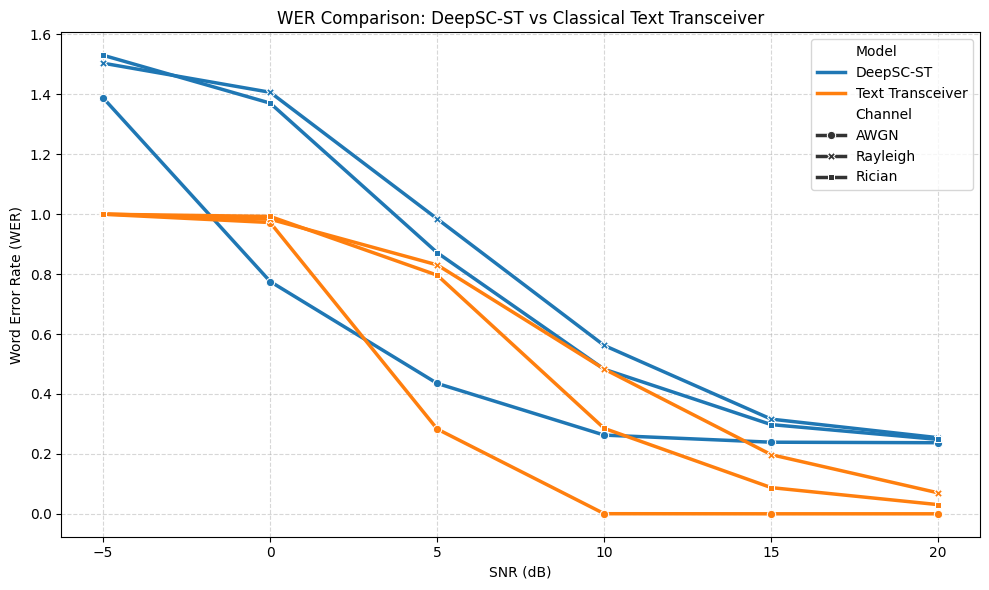

Plots saved successfully!


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------- CER Comparison ----------------
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=comparison_df,
    x="SNR (dB)",
    y="CER",
    hue="Model",
    style="Channel",
    markers=True,
    dashes=False,
    linewidth=2.5
)

plt.title("CER Comparison: DeepSC-ST vs Classical Text Transceiver")
plt.xlabel("SNR (dB)")
plt.ylabel("Character Error Rate (CER)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig("CER_Comparison.png", dpi=300, bbox_inches="tight")
plt.savefig("CER_Comparison.pdf", bbox_inches="tight")

plt.show()


# ---------------- WER Comparison ----------------
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=comparison_df,
    x="SNR (dB)",
    y="WER",
    hue="Model",
    style="Channel",
    markers=True,
    dashes=False,
    linewidth=2.5
)

plt.title("WER Comparison: DeepSC-ST vs Classical Text Transceiver")
plt.xlabel("SNR (dB)")
plt.ylabel("Word Error Rate (WER)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig("WER_Comparison.png", dpi=300, bbox_inches="tight")
plt.savefig("WER_Comparison.pdf", bbox_inches="tight")

plt.show()

print("Plots saved successfully!")